## Example: OPC cement hydration using the Parrot-Killoh model  

**Authors: R.A. Patel, G.D. Miron**

**Modified: M. H. Moreira, and Claude**

In [1]:
# folder run contains the file hydration.py where several functions are implemented and imported bellow 
from run.hydration import run_hydration
from run.hydration import parrot_killoh
from run.hydration import to_phase_first_dict
from run.hydration import plot_bars
from run.hydration import phase_plot
import pandas as pd

[2026-11-23 15:01:42.607] [gems3k] [info] Home directory is /Users/khatiromar


Matplotlib is building the font cache; this may take a moment.


In [3]:
# input recipe
clinker_phases = {}
clinker_phases["C3S"]=64.6 
clinker_phases["C2S"]=9.3
clinker_phases["C3A"]=7.4
clinker_phases["C4AF"]=7.8
CSH2 = 2.2 # gypsum

wc = 0.44 # water/cement
RH = 1 # relative humidity
T = 25 # temperature
fineness = 385 

In [4]:
# Run parrot killoh clinker hydration, returns overall rate of cement clinker dissolution - degree of hydration DoH
DoH = parrot_killoh(wc, RH, T, fineness) 

In [5]:
# run hydration
# GEMS system is initialized and calculations run for each time step. Hydration code can be seen in /run/hydration.py 
# returns the volume fraction, masses and densities of phases 
vol_frac, mass_frac, density = run_hydration(clinker_phases, wc, CSH2, T, DoH)

{'C3S': 64.6, 'C2S': 9.3, 'C3A': 7.4, 'C4AF': 7.8, 'H2O@': 44.0, 'Gp': 2.2}
Time--> 0.0 : OK after GEM calculation with LPP AIA
Time--> 0.1 : OK after GEM calculation with SIA
Time--> 1 : OK after GEM calculation with SIA
Time--> 3 : OK after GEM calculation with SIA
Time--> 7 : OK after GEM calculation with SIA
Time--> 28 : OK after GEM calculation with SIA
Time--> 30 : OK after GEM calculation with SIA
Time--> 60 : OK after GEM calculation with SIA
Time--> 90 : OK after GEM calculation with SIA
Time--> 365 : OK after GEM calculation with SIA
Time--> 730 : OK after GEM calculation with SIA
Time--> 1000 : OK after GEM calculation with SIA
Time--> 2000 : OK after GEM calculation with SIA


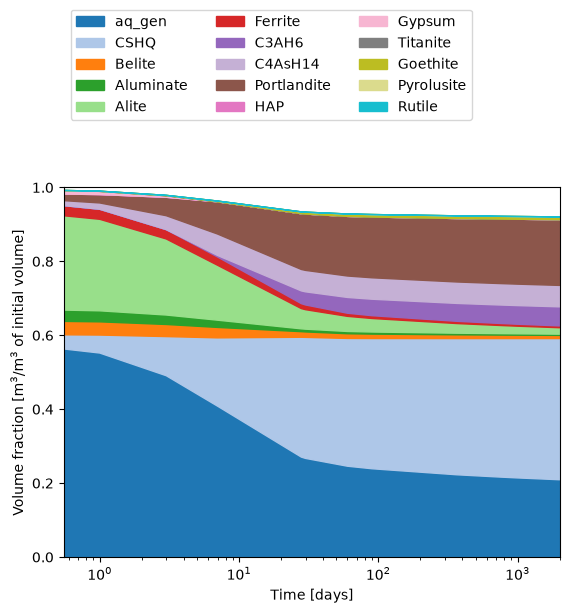

In [6]:
# function to rearange and plot the results
gems_vol_frac_phase_first = to_phase_first_dict(vol_frac)
gems_masses_phase_first = to_phase_first_dict(mass_frac)
p2 = phase_plot(gems_vol_frac_phase_first)
p2.show()

In [7]:
# write results to file
gems_vol_frac_phase_first.update((x, y*100) for x, y in gems_vol_frac_phase_first.items())
pd_vol_frac = pd.DataFrame.from_dict(gems_vol_frac_phase_first) 
pd_vol_frac.to_csv('results_hydration.csv')